# 4 · How sure are we? Doubly robust estimation, uncertainty, robustness, and the write-up

Notebook 3 got close to the benchmark. A careful researcher's next question is: **would I have gotten close without knowing the answer?** This notebook stress-tests the result the way you'd have to in a real analysis.

**What you'll learn**
- Doubly robust (AIPW) estimation: combining an outcome model with weights
- Bootstrap confidence intervals, and when the bootstrap fails
- Specification sensitivity: which choices move the answer
- Placebo (falsification) tests, and what a failed one means
- How to write the result up for leaders, and how to talk about it in an interview

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from utils import loadData, addFeatures

pd.set_option("display.float_format", lambda v: f"{v:,.0f}")
experiment, cps = loadData()
expTreated = experiment.loc[experiment.treat == 1, "re78"]
expControl = experiment.loc[experiment.treat == 0, "re78"]
benchmark = expTreated.mean() - expControl.mean()
benchmarkSe = np.sqrt(expTreated.var(ddof=1) / len(expTreated) + expControl.var(ddof=1) / len(expControl))
observational = addFeatures(pd.concat([experiment[experiment.treat == 1], cps], ignore_index=True))

psFormula = "treat ~ age + age2 + educ + educ2 + black + hisp + marr + nodegree + re74k + re75k + u74 + u75"
outcomeX = "age + age2 + educ + educ2 + black + hisp + marr + nodegree + re74 + re75 + u74 + u75"

## Part A · Doubly robust estimation (AIPW)

Regression models the **outcome**. IPW models **who gets treated**. Each is biased if its model is wrong. A doubly robust estimator uses both, and it stays consistent if **either one** is right. That's two chances instead of one.

For the ATT:
1. Fit an outcome model on the comparison group only: $\hat m_0(x) \approx E[Y \mid T=0, X=x]$. It predicts what anyone *would have* earned without the program.
2. Take residuals $r_i = Y_i - \hat m_0(X_i)$ for everyone.
3. The treated residuals estimate the effect; the weighted comparison residuals correct for whatever the outcome model got wrong:

$$\widehat{ATT}_{DR} = \frac{1}{n_1}\sum_{T_i=1} r_i \;-\; \frac{\sum_{T_i=0} w_i\, r_i}{\sum_{T_i=0} w_i}, \qquad w_i = \frac{\hat e(X_i)}{1-\hat e(X_i)}$$

If the outcome model is perfect, comparison residuals average zero and the second term vanishes. If the outcome model is off but the weights are right, the second term subtracts exactly the error.

We wrap the whole pipeline in one function, so we can rerun it for the bootstrap and for different model choices.

In [2]:
def estimateAtt(data, psF=psFormula, outF=outcomeX, outcome="re78"):
    # 1. propensity scores
    d = data.copy()
    d["ps"] = smf.logit(psF, data=d).fit(disp=0, maxiter=300).predict(d)
    # 2. trim to common support
    lower, upper = d.loc[d.treat == 1, "ps"].min(), d.loc[d.treat == 0, "ps"].max()
    d = d[(d.ps >= lower) & (d.ps <= upper)].copy()
    d["w"] = np.where(d.treat == 1, 1.0, d.ps / (1 - d.ps))
    isT, isC = d.treat == 1, d.treat == 0
    # 3. ipw
    ipw = d.loc[isT, outcome].mean() - np.average(d.loc[isC, outcome], weights=d.loc[isC, "w"])
    # 4. doubly robust: outcome model fit on comparison people only
    m0 = smf.ols(f"{outcome} ~ {outF}", data=d[isC]).fit()
    resid = d[outcome] - m0.predict(d)
    dr = resid[isT].mean() - np.average(resid[isC], weights=d.loc[isC, "w"])
    return {"ipw": ipw, "dr": dr, "n_treated": int(isT.sum()), "n_control": int(isC.sum())}

point = estimateAtt(observational)
print(f"IPW ATT:            ${point['ipw']:,.0f}")
print(f"doubly robust ATT:  ${point['dr']:,.0f}")
print(f"benchmark:          ${benchmark:,.0f}")

IPW ATT:            $1,719
doubly robust ATT:  $1,458
benchmark:          $1,794


## Part B · Uncertainty: the bootstrap

We need a confidence interval, and there's no simple formula once you estimate propensity scores, trim, and weight. The **bootstrap** gets one by brute force:

1. Resample the data with replacement (treated and comparison separately, so each sample keeps the same group sizes).
2. Rerun the **entire** pipeline, including refitting the propensity model.
3. Repeat a few hundred times. The middle 95% of the estimates is the interval.

Refitting everything matters: the propensity scores are estimates too, and their uncertainty belongs in the interval.

> **A caveat worth knowing for interviews:** the plain bootstrap is known to be unreliable for nearest-neighbor *matching* (Abadie & Imbens, 2008), which is why we bootstrap IPW and DR here. For matching, people use the Abadie-Imbens standard error formula instead.

In [3]:
rng = np.random.default_rng(42)
treatedRows = observational[observational.treat == 1]
controlRows = observational[observational.treat == 0]

nBoot = 200  # raise to 1,000 for a final analysis; 200 runs in well under a minute
draws = []
start = time.time()
for b in range(nBoot):
    sample = pd.concat([
        treatedRows.sample(len(treatedRows), replace=True, random_state=rng.integers(1e9)),
        controlRows.sample(len(controlRows), replace=True, random_state=rng.integers(1e9)),
    ])
    est = estimateAtt(sample)
    draws.append((est["ipw"], est["dr"]))
draws = pd.DataFrame(draws, columns=["ipw", "dr"])
print(f"{nBoot} bootstrap reps in {time.time() - start:.0f}s")

ci = draws.quantile([0.025, 0.975]).T
ci.columns = ["ci_low", "ci_high"]
ci.insert(0, "estimate", [point["ipw"], point["dr"]])
ci.loc["experiment (benchmark)"] = [benchmark, benchmark - 1.96 * benchmarkSe, benchmark + 1.96 * benchmarkSe]
ci

200 bootstrap reps in 19s


,estimate,ci_low,ci_high
ipw,"1,719",414,"3,011"
dr,"1,458",115,"2,775"
experiment (benchmark),"1,794",479,"3,109"


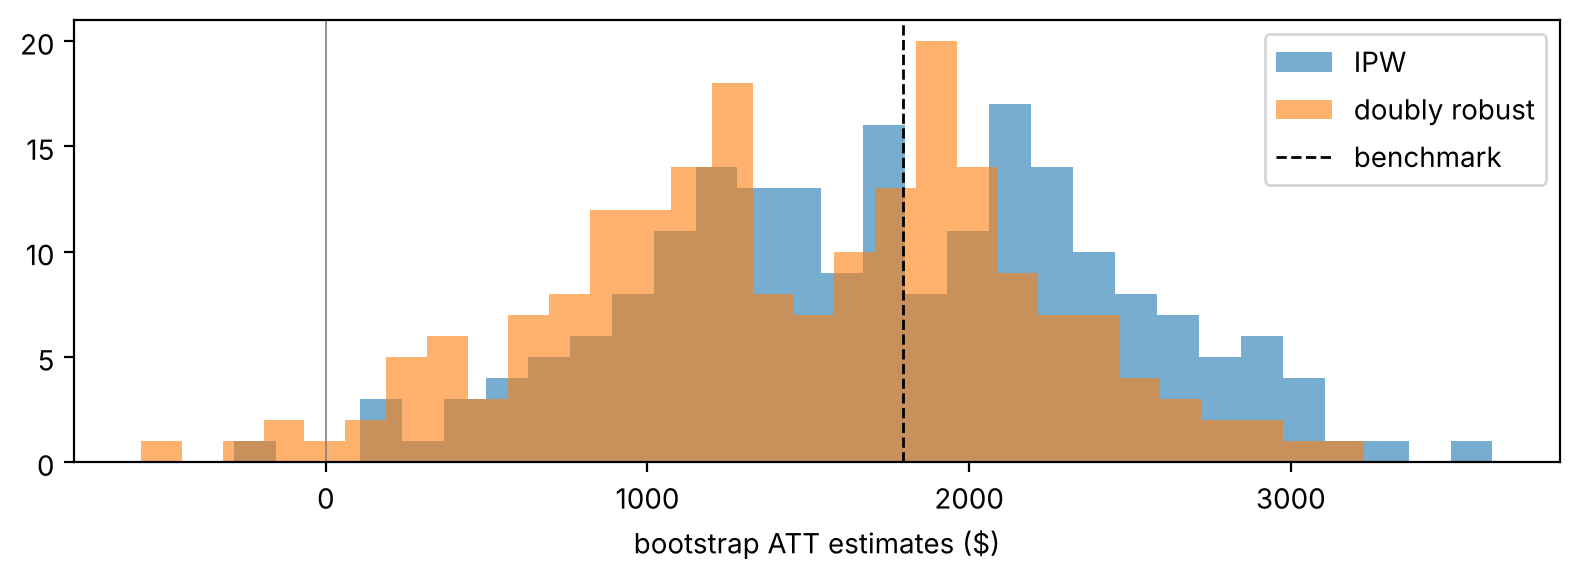

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(draws.ipw, bins=30, alpha=0.6, label="IPW")
ax.hist(draws.dr, bins=30, alpha=0.6, label="doubly robust")
ax.axvline(benchmark, color="black", ls="--", lw=1, label="benchmark")
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("bootstrap ATT estimates ($)")
ax.legend()
plt.tight_layout()
plt.show()

Both intervals are about as wide as the experiment's, even though we started with 16,000 comparison people, and the doubly robust interval comes close to zero at its low end. Remember the effective sample size from notebook 3: only about a hundred comparison people really count. **Observational data rarely buys you precision for free.** Whether an interval includes zero is the first thing a skeptical leader will ask about, so always report it.

## Part C · Specification sensitivity: which choices move the answer?

A result you can only get with one exact model isn't a result. Rerun the pipeline with different sets of covariates in the propensity model.

In [5]:
specs = {
    "demographics only": "age + educ + black + hisp + marr + nodegree",
    "+ 1975 earnings": "age + educ + black + hisp + marr + nodegree + re75k + u75",
    "+ 1974 and 1975 earnings": "age + educ + black + hisp + marr + nodegree + re74k + re75k + u74 + u75",
    "full (squares too)": "age + age2 + educ + educ2 + black + hisp + marr + nodegree + re74k + re75k + u74 + u75",
}
rows = []
for name, x in specs.items():
    est = estimateAtt(observational, psF=f"treat ~ {x}", outF=x.replace("re74k", "re74").replace("re75k", "re75"))
    rows.append({"propensity model": name, "IPW": est["ipw"], "doubly robust": est["dr"],
                 "comparison people kept": est["n_control"]})
sensitivity = pd.DataFrame(rows).set_index("propensity model")
sensitivity

,IPW,doubly robust,comparison people kept
propensity model,,,
demographics only,"-2,774","-2,900",12727
+ 1975 earnings,"1,227","1,214",5766
+ 1974 and 1975 earnings,"1,440","1,492",6101
full (squares too),"1,719","1,458",4458


This table is the real lesson of the LaLonde literature:

- With **demographics only**, the estimate is badly wrong. Age, race, and education don't capture who these people were economically.
- Adding **prior earnings** is what moves the estimate toward the benchmark. A second year of earnings history helps further.

**Which confounders you have matters far more than which estimator you use.** Matching vs. IPW vs. DR changed the answer by a few hundred dollars. Leaving out earnings history changed it by thousands, and flipped the sign.

In HR: if you evaluate mentoring without prior performance ratings, starting pay, or how people were hired, no method will save you.

## Part D · Placebo test: an "effect" that should be zero

If our adjustment really makes the groups comparable, it should show **no effect on something the program couldn't have changed**. Take 1975 earnings as a fake outcome, adjust for everything *else* (including 1974 earnings), and estimate the "effect."

In [6]:
placeboX = "age + age2 + educ + educ2 + black + hisp + marr + nodegree + re74k + u74"
placebo = estimateAtt(observational, psF=f"treat ~ {placeboX}", outF=placeboX, outcome="re75")
experimentPlacebo = experiment.loc[experiment.treat == 1, "re75"].mean() - experiment.loc[experiment.treat == 0, "re75"].mean()

print(f"placebo 'effect' on 1975 earnings, observational (IPW): ${placebo['ipw']:,.0f}")
print(f"placebo 'effect' on 1975 earnings, observational (DR):  ${placebo['dr']:,.0f}")
print(f"same comparison inside the experiment:                ${experimentPlacebo:,.0f}")

placebo 'effect' on 1975 earnings, observational (IPW): $-1,414
placebo 'effect' on 1975 earnings, observational (DR):  $-1,561
same comparison inside the experiment:                $265


**The placebo test doesn't come back clean.** Inside the experiment, 1975 earnings barely differ. In the adjusted observational comparison, participants look about $1,400 to $1,600 *poorer* in 1975, even after adjusting for 1974.

The likely reason has a name: **Ashenfelter's dip.** People tend to enter job training right after their earnings fall. Two people with the same 1974 earnings can be on very different paths, and the one heading down is the one who signs up. Controlling for one year of history doesn't capture the trajectory. (Some participants may also have started the program during 1975, so it isn't a perfectly clean placebo either way.)

What does that mean for our estimate?
- Treat it as a **warning** that unconfoundedness is shaky with only two years of history.
- Don't hide it. Report the near-benchmark estimate *and* the failed placebo. In real work, you wouldn't have the benchmark to reassure you.

**HR version:** people may join mentoring right after a bad quarter, or ask for a raise right after an outside offer. A placebo test on last year's outcome catches that kind of selection.

## Part E · The assumptions checklist

| Assumption | What it means | How we checked | Status here |
|---|---|---|---|
| Unconfoundedness | No unmeasured factor drives both enrollment and earnings | Argument + placebo test | Questionable (failed placebo) |
| Overlap | Every participant has comparable non-participants | Propensity histogram, trimming | OK after trimming; ~11,500 comparison people dropped |
| Correct model | Propensity and/or outcome model shaped right | Balance tables, DR, spec sensitivity | Moves a lot without earnings history |
| No interference (SUTVA) | One person's program doesn't change another's outcome | Argument | Plausible |
| No bad controls | Nothing in X is affected by the program | Only pre-program variables used | OK |

## Part F · The write-up for leaders

A one-page structure that works for any program evaluation. Here it is filled in for this study.

> **Question.** Did the NSW work program raise participants' 1978 earnings, and could we have known without the experiment?
>
> **Data.** 185 participants; 15,992 comparison adults from a national survey. Pre-program demographics and earnings for 1974 and 1975.
>
> **Approach.** Participants and the comparison group were very different before the program (most participants had no earnings in 1974–75). We kept only comparison people who resembled participants, then reweighted them so the groups matched on all pre-program measures, and checked that the match worked.
>
> **Result.** Adjusted estimates of roughly $1,450 to $1,700 in added annual earnings, close to the experimental result of about $1,800. Uncertainty is wide (see bootstrap intervals).
>
> **How much to trust it.** The answer depends heavily on having earnings history; without it, the estimate is wrong. A placebo test suggests participants were on a falling earnings path the data don't fully capture, so some bias likely remains.
>
> **Recommendation.** Treat the adjusted estimate as supportive, not conclusive. When a decision depends on it, run a randomized pilot (for example, a staggered rollout).

## Part G · Interview talking points

**The 60-second version**
> "I worked through the LaLonde job-training data, where an experiment gives the true effect of about $1,800. A naive comparison against survey data says the program *cost* $8,500, which is pure selection bias. Regression gets closer but extrapolates across groups that barely overlap. After trimming to common support, matching, IPW, and a doubly robust estimator all land near the benchmark. But the results swing by thousands depending on whether prior earnings are in the model, and a placebo test on 1975 earnings fails, which points to Ashenfelter's dip. So my takeaway is that knowing the selection process matters more than which estimator you pick."

**Likely follow-ups, and what to say**
- *"How would you apply this to a pay raise and attrition?"* Raises go to high performers, who also get outside offers, so a naive comparison is confounded. I'd adjust for prior performance, level, tenure, and comp ratio. I'd use the timing of the merit cycle where possible. And I'd run a placebo on pre-raise attrition risk.
- *"What if you can't measure the key confounder?"* Say so. Run a sensitivity analysis on how strong an unmeasured confounder would have to be to erase the effect. Push for a randomized or staggered rollout.
- *"Why ATT and not ATE?"* The question was whether it worked for participants. If leaders want to mandate the program for everyone, ATE is the target, and overlap gets harder.
- *"Matching or weighting?"* Both rely on the same assumptions. I'd show both plus doubly robust; agreement is reassuring, disagreement is a finding.

---

### Your turn (optional extensions)
1. Raise `nBoot` to 1,000 and see whether the intervals change.
2. Swap the propensity model for a gradient-boosted classifier (`sklearn.ensemble.HistGradientBoostingClassifier`). Does a more flexible model get closer to the benchmark, or just overfit?
3. Try ATE weights instead of ATT weights: treated $1/e$, controls $1/(1-e)$. Why do they blow up here?
4. Then open `../hr-sql/02_mentoring_effect.ipynb` and do all of this on HR data you built yourself with SQL.